# Virtual detectors in 4D-STEM

This notebook makes bright field, dark field and annular dark field images from a 4D-STEM scan
with pyEMAPS, step by step. It follows the *adf.py* and *convert_image.py* samples, one step per
cell.

You'll:

1. download a 4D-STEM test scan and look at its diffraction patterns;
2. make images with virtual detectors: bright field (BF), annular dark field (ADF) and dark
   field (DF);
3. check pyEMAPS' result against a sum you compute yourself;
4. make an image with a detector mask, including one you draw yourself.

**4D-STEM in brief.** In scanning transmission electron microscopy (STEM), a focused electron
probe is scanned across the sample. In 4D-STEM, a camera records the whole diffraction pattern at
every probe position: two scan coordinates and two detector coordinates, hence 4D. A conventional
STEM detector adds up the electrons that land on a fixed region of the pattern: a disk on the
direct beam for bright field, a ring around it for annular dark field. With the whole pattern
recorded, you choose that region after the experiment: a **virtual detector**. Each scan position
gives one pixel of the image.

**A licensed feature.** The 4D-STEM functions need an activated pyEMAPS license. `pyemaps -l
trial`, run in a terminal with an internet connection, activates a free 7-day trial; for a full
license, contact support@emlabsoftware.com. Step 1 checks it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. Step 2 downloads the test scan, 472 MB, once.

## Step 1: Import pyEMAPS and check the license

`StackImage` holds experimental images and runs the 4D-STEM analyses. Files the notebook writes
go to the pyEMAPS data folder: the folder named by the `PYEMAPS_DATA` environment variable, or the
current folder if it isn't set.

In [1]:
import hashlib
import os
import shutil
import urllib.request
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle

import pyemaps
from pyemaps import E_NPY, EM_INT, StackImage, stem4d

print('pyEMAPS', version('pyemaps'))
if stem4d.check_license_once() == stem4d.LICENSE_ACTIVE:
    print('License: active')
else:
    print('No active license: run "pyemaps -l trial" in a terminal for a 7-day trial, '
          'or contact support@emlabsoftware.com.')

DATA_DIR = os.environ.get('PYEMAPS_DATA') or os.getcwd()
SAMPLES = os.path.join(os.path.dirname(pyemaps.__file__), 'samples')

pyEMAPS 2.2.0
License: active


## Step 2: Download the test scan

*adftest900.im3* is a 4D-STEM test scan published by EMLab Solutions on
[Zenodo](https://zenodo.org/records/14028793) under the CC BY 4.0 license. The cell downloads it
into the data folder, unless it's already there, and checks it against its published MD5
checksum. The download is 472 MB, so it can take a few minutes.

In [2]:
URL = 'https://zenodo.org/records/14028793/files/adftest900.im3?download=1'
MD5 = '81d8f8cad15f7fb51c2845505e7209a7'
IMAGE_FILE = os.path.join(DATA_DIR, 'adftest900.im3')


def md5sum(path):
    digest = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


if not os.path.exists(IMAGE_FILE):
    print('Downloading adftest900.im3, 472 MB ...')
    urllib.request.urlretrieve(URL, IMAGE_FILE + '.part')
    os.replace(IMAGE_FILE + '.part', IMAGE_FILE)

if md5sum(IMAGE_FILE) == MD5:
    print('adftest900.im3: checksum OK')
else:
    print('adftest900.im3: checksum wrong; delete the file and run this cell again')

adftest900.im3: checksum OK


## Step 3: Look at the diffraction patterns

The file is in pyEMAPS' small-header format: an 8-byte header of four 16-bit integers (the
width, the height, the number of stacks and the data type), then the stacks, one after another.
Each stack is the diffraction pattern at one scan position.

NumPy can read it directly. `np.memmap` maps the file into memory without loading it all, so
each pattern is read only when it's used. (With emaps 2.0.0 and earlier,
`StackImage.loadImage()` misreads 16-bit files like this one, which is another reason to read
the patterns with NumPy here.)

In [3]:
width, height, nstacks, dtype = (int(v) for v in np.fromfile(IMAGE_FILE, dtype='<i2', count=4))
print(f'{nstacks} patterns of {width} x {height} pixels; data type {dtype} '
      '(11: 16-bit integers, several stacks)')

patterns = np.memmap(IMAGE_FILE, dtype='<i2', mode='r', offset=8,
                     shape=(nstacks, height, width))

SCAN = 30                        # scan positions per row
print(f'Scan: {nstacks // SCAN} rows of {SCAN} positions')

900 patterns of 512 x 512 pixels; data type 11 (11: 16-bit integers, several stacks)
Scan: 30 rows of 30 positions


Here are the pattern at the first scan position, and the average of all 900. A
logarithmic colour scale shows the weak scattering next to the bright direct beam.

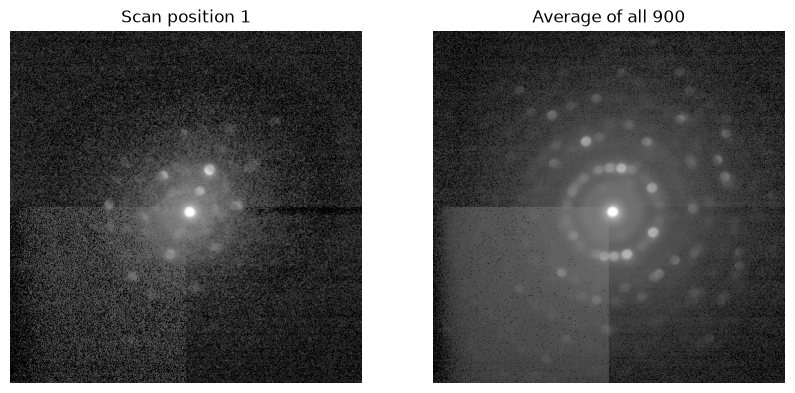

In [4]:
from matplotlib.colors import LogNorm

mean = patterns.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, image, title in zip(axes, (patterns[0], mean), ('Scan position 1', 'Average of all 900')):
    ax.imshow(np.clip(image, 1, None), cmap='gray', norm=LogNorm())
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

Two things stand out:

- The average shows **rings of spots**. The sample is made of grains in different
  orientations, and each grain's pattern adds its own spots; summed over the scan, the spots of
  the same reflections sit on rings around the direct beam.
- The lower-left quarter of every pattern has a **higher background**, with straight edges
  along the pattern's center lines. That's the camera, not the sample. A virtual detector that
  covers it picks up the extra background.

Every virtual detector is placed relative to the direct beam, so first find it: the
brightest pixel of the average pattern. The direct beam's radius shows in how the average
intensity falls off around it.

In [5]:
row, col = np.unravel_index(mean.argmax(), mean.shape)
CENTER = (float(col), float(row))                 # (column, row), as pyEMAPS expects
print(f'Direct beam at column {col}, row {row}')

yy, xx = np.indices(mean.shape)
radius = np.hypot(xx - col, yy - row)                 # each pixel's distance from the beam
bins = radius.astype(int).ravel()
profile = np.bincount(bins, mean.ravel()) / np.bincount(bins)
print('Average intensity at radius 0, 4, 8, 12, 16 px:', np.round(profile[[0, 4, 8, 12, 16]]))

Direct beam at column 263, row 263
Average intensity at radius 0, 4, 8, 12, 16 px: [9187. 8061. 1764.  230.  121.]


The intensity drops by a factor of ten within about 10 pixels: that's the edge of the direct
beam. Outside it, the scattering falls off slowly, with a ring around 60 pixels.

## Step 4: Bright field, annular dark field and dark field

`generateBDF` adds up each pattern's pixels inside a virtual detector: a disk or ring with the
`center` and the inner and outer radii `rads`, in pixels. `scol` is the number of scan positions
per row, which shapes the output into an image. It returns a status, 0 on success, and the image
as a flat list of values.

- **Bright field (BF):** a disk on the direct beam, radius 8 pixels. It records the electrons
  that pass the sample unscattered.
- **Annular dark field (ADF):** a ring from 50 to 200 pixels, as in the *adf.py* sample. It
  records the electrons scattered to larger angles.
- **Dark field (DF):** the *adf.py* sample's off-axis detector, a disk of radius 200 pixels
  centred at the pattern's left edge. It collects scattering on one side, but not the direct
  beam.

In [6]:
DETECTORS = {
    'Bright field':         (CENTER, (0.0, 8.0)),
    'Annular dark field':   (CENTER, (50.0, 200.0)),
    'Dark field':           ((1.0, 256.0), (0.0, 200.0)),
}

images = {}
for name, (center, rads) in DETECTORS.items():
    ret, data = StackImage(IMAGE_FILE, ndtype=EM_INT).generateBDF(center=center, rads=rads,
                                                                  scol=SCAN)
    images[name] = np.array(data, dtype=float).reshape(-1, SCAN)
    print(f'{name}: status {ret}, image {images[name].shape[0]} x {images[name].shape[1]}')

Bright field: status 0, image 30 x 30


Annular dark field: status 0, image 30 x 30


Dark field: status 0, image 30 x 30


Each detector, drawn on the average pattern, and the image it gives:

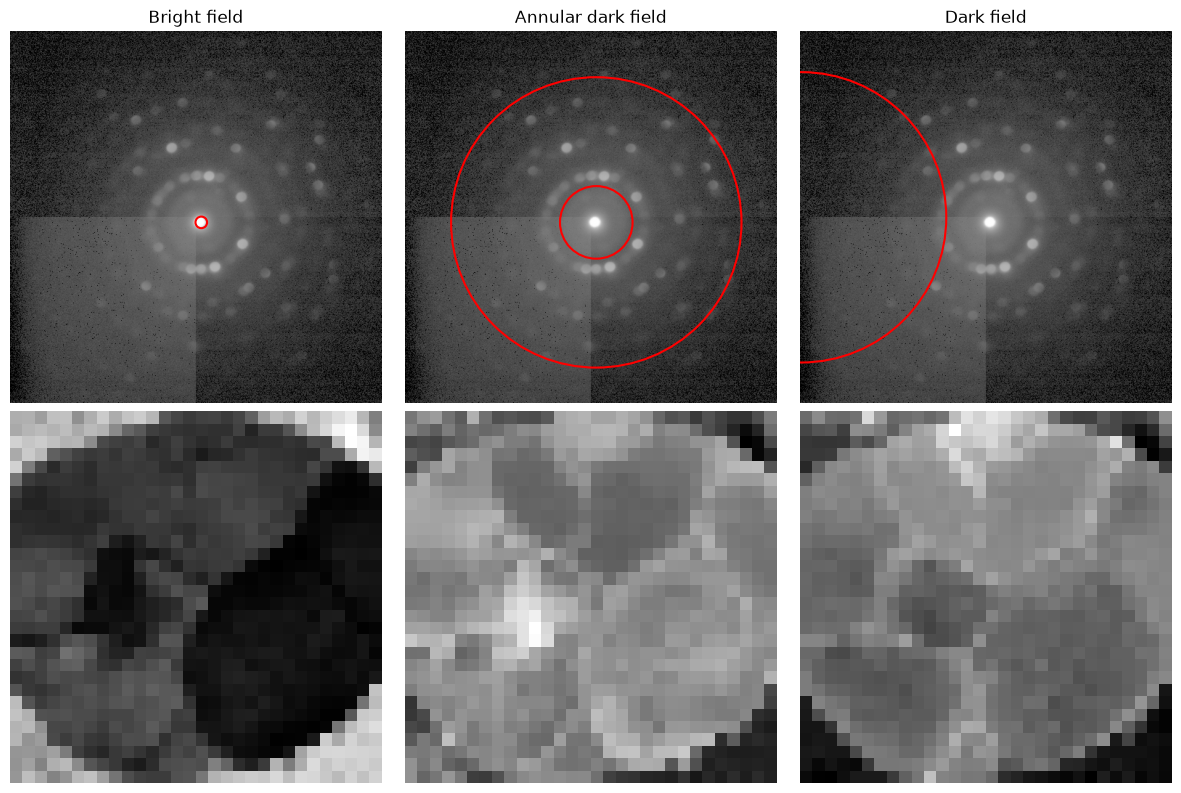

Correlation between the BF and ADF images: -0.72


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for k, (name, (center, (r_in, r_out))) in enumerate(DETECTORS.items()):
    ax = axes[0, k]
    ax.imshow(np.clip(mean, 1, None), cmap='gray', norm=LogNorm())
    for r in (r_in, r_out):
        if r > 0:
            ax.add_patch(Circle(center, r, fill=False, color='red', linewidth=1.5))
    ax.set_title(name)
    ax.set_axis_off()

    ax = axes[1, k]
    ax.imshow(images[name], cmap='gray')
    ax.set_axis_off()
plt.tight_layout()
plt.show()

bf, adf = images['Bright field'].ravel(), images['Annular dark field'].ravel()
print(f'Correlation between the BF and ADF images: {np.corrcoef(bf, adf)[0, 1]:.2f}')

Bright field and annular dark field show largely reversed contrast, with a correlation of
−0.72: where the sample scatters strongly, electrons leave the direct beam (darker in BF) and land
in the ring (brighter in ADF). The dark field image depends on which part of the pattern its
detector covers; try moving it in the exercises.

## Step 5: Check it yourself

A virtual detector is just a sum over pixels, so NumPy can make the same image. Here is the ADF
image again, summed directly from the patterns:

In [8]:
ring = (radius >= 50) & (radius <= 200)
mine = np.array([pattern[ring].sum() for pattern in patterns], dtype=float).reshape(-1, SCAN)

print('Largest difference from pyEMAPS:', np.abs(mine - images['Annular dark field']).max())

Largest difference from pyEMAPS: 0.0


The two agree exactly. pyEMAPS does the same sum in compiled code, which is faster on large
scans.

## Step 6: Detector masks

A detector doesn't have to be a disk or a ring. `generateMaskedImage` takes a **mask**, an image
the size of a pattern: pixels above 0.5 belong to the detector. *mask.im3*, which comes with
pyEMAPS, is the mask of the *adf.py* sample:

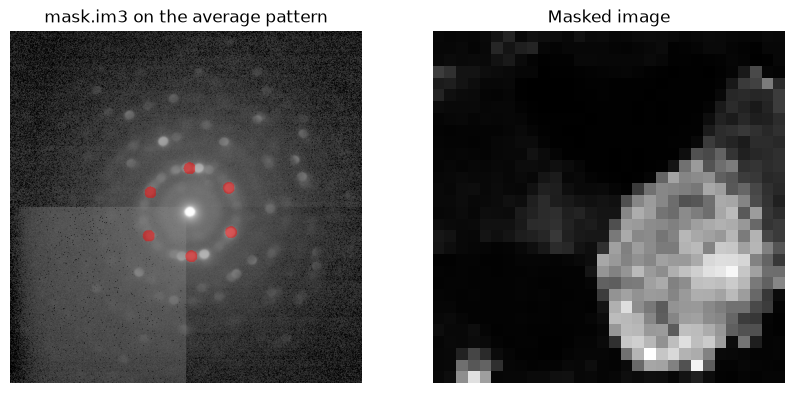

In [9]:
MASK_FILE = os.path.join(SAMPLES, 'mask.im3')
mask = np.fromfile(MASK_FILE, dtype='<f4', offset=8).reshape(height, width)   # float32 pixels

ret, data = StackImage(IMAGE_FILE, ndtype=EM_INT).generateMaskedImage(MASK_FILE, SCAN)
masked = np.array(data, dtype=float).reshape(-1, SCAN)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(np.clip(mean, 1, None), cmap='gray', norm=LogNorm())
axes[0].imshow(np.ma.masked_where(mask <= 0.5, mask), cmap='autumn', alpha=0.5)
axes[0].set_title('mask.im3 on the average pattern')
axes[1].imshow(masked, cmap='gray')
axes[1].set_title('Masked image')
for ax in axes:
    ax.set_axis_off()
plt.show()

The mask picks six spots on the ring around 60 pixels, a hexagon from one grain's pattern.
Only one region of the scan lights up: the grain whose diffraction spots fall on the mask. A
mask on chosen spots gives a **dark field image** of the crystal regions that produce them.

### A mask of your own

Draw a mask as a NumPy array, convert it to pyEMAPS' format with `convertImage`, and use it. This
one is a narrow ring on the scattering around 60 pixels from the direct beam. `convertImage`
saves the file in the `sh_converted` folder of the data folder, and returns its path.

The numpy image was successfully converted to pyEMAPS image format and saved as C:\pyemaps_data\sh_converted\numpy_image_20261114_213154.im3


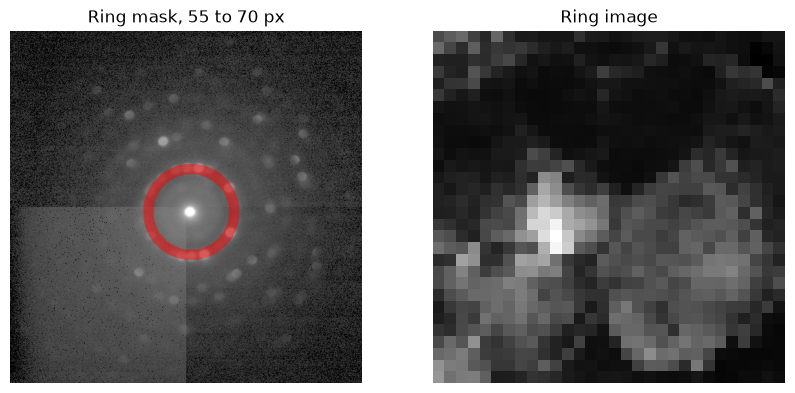

In [10]:
own_mask = ((radius >= 55) & (radius <= 70)).astype(np.float32)
own_mask_file = StackImage.convertImage(own_mask, nformat=E_NPY)

ret, data = StackImage(IMAGE_FILE, ndtype=EM_INT).generateMaskedImage(own_mask_file, SCAN)
ring_image = np.array(data, dtype=float).reshape(-1, SCAN)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(np.clip(mean, 1, None), cmap='gray', norm=LogNorm())
axes[0].imshow(np.ma.masked_where(own_mask <= 0.5, own_mask), cmap='autumn', alpha=0.5)
axes[0].set_title('Ring mask, 55 to 70 px')
axes[1].imshow(ring_image, cmap='gray')
axes[1].set_title('Ring image')
for ax in axes:
    ax.set_axis_off()
plt.show()

## Converting other images

`convertImage` also converts raw image files: pixel data with no header, or a header of known
size. You give the dimensions and where the data starts. The *convert_image.py* sample converts
*raw.img*, a 256 × 256 image of 4-byte floats with no header. The converted file goes into an
`sh_converted` folder next to the input, so the cell first copies *raw.img* into the data
folder.

The image file C:\pyemaps_data\raw.img was successfully converted to pyEMAPS image format and saved as C:\pyemaps_data\sh_converted\raw.im3


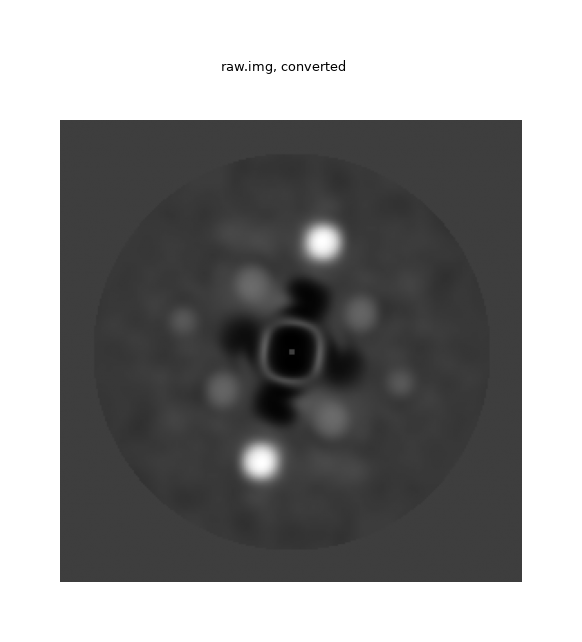

In [11]:
raw_file = shutil.copy(os.path.join(SAMPLES, 'raw.img'), DATA_DIR)
converted = StackImage.convertImage(raw_file,
                                    dim=(256, 256, 1),   # width, height and number of stacks
                                    noffset=0)           # bytes before the image data

image = StackImage(converted)
image.loadImage()
image.viewExpImage(title='raw.img, converted')

## Try it yourself

1. **Detector angles.** Make ADF images with inner radii of 20, 50 and 100 pixels. How does the
   contrast change as the detector collects only higher angles?
2. **Bright field size.** Make BF images with radii of 4, 8 and 16 pixels. What happens once the
   detector is larger than the direct beam?
3. **Dark field.** Place a small disk detector, radius 10 pixels, on the ring around 60 pixels,
   at different angles around the direct beam. Do the images differ?
4. **Half-disk masks.** Make two masks, the left and the right halves of the direct beam, and
   subtract the two images. Where the sample deflects the beam, one half receives more
   electrons than the other: this is the idea behind differential phase contrast imaging.

## Next

- The pattern indexing notebook, [al_ediom.ipynb](al_ediom.ipynb): indexing an experimental
  diffraction pattern against a simulated database.
- The references for [`generateBDF`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.generateBDF),
  [`generateMaskedImage`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.generateMaskedImage)
  and [`convertImage`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.convertImage).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 8, *Coherent Nanoprobes. STEM. Defects and Amorphous Materials*, for STEM with a
  focused probe.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3), a newer and
broader book by the same authors:

- chapter 9, *Electron Detectors*, for the cameras that record 4D-STEM data;
- chapter 10, *Instrumentation and Experimental Techniques*, for the microscope side of the
  experiment.